# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Indica qué harías: ¿imputar, eliminar, ignorar?
    - users['city'] 469 faltantes, 11.7% / Investigar y evaluar imputación
    - users['churn_date'] 3534 faltantes, 88.3% / Ignorar (**churn date** significa fecha de baja, dato faltante cuando los clientes siguen activos)
    - usage['date'] 50 faltantes, 0.1% / Imputar con rango de fechas (si es posible) o eliminar
    - usage['duration'] 22076 faltantes, 55.1% / Investigar y evaluar imputación
    - usage['lenght'] 17896 faltantes, 44.7% / Investigar y evaluar imputación


### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users[['user_id','age']].describe(), users[['user_id','age']].isnull().sum()

(            user_id          age
 count   4000.000000  4000.000000
 mean   11999.500000    33.739750
 std     1154.844867   123.232257
 min    10000.000000  -999.000000
 25%    10999.750000    32.000000
 50%    11999.500000    47.000000
 75%    12999.250000    63.000000
 max    13999.000000    79.000000,
 user_id    0
 age        0
 dtype: int64)

- La columna `user_id` presenta coherencia, los datos corresponden al consecutivo de 4 mil registros. Los datos están limpios.
- La columna `age` presenta un sentinel (-999), esto hace que la desviación estándar esté fuera de los rangos de coherencia y que los valores de la media y la mediana no sean confiables. Es necesario evaluar o reemplazar.

In [13]:
# explorar columnas numéricas de usage
usage[['id','user_id','duration','length']].describe(), usage[['id','user_id','duration','length']].isnull().sum()

(                id       user_id      duration        length
 count  40000.00000  40000.000000  17924.000000  22104.000000
 mean   20000.50000  12002.405975      5.202237     52.127398
 std    11547.14972   1157.279564      6.842701     56.611183
 min        1.00000  10000.000000      0.000000      0.000000
 25%    10000.75000  10996.000000      1.437500     37.000000
 50%    20000.50000  12013.000000      3.500000     50.000000
 75%    30000.25000  13005.000000      6.990000     64.000000
 max    40000.00000  13999.000000    120.000000   1490.000000,
 id              0
 user_id         0
 duration    22076
 length      17896
 dtype: int64)

- Las columnas `id` y `user_id` presentan coherencia, `id` corresponde a 40 mil registros y `user_id` corresponde a 4 mil registros, este dato es similar al del df`users`. Los datos están limpios.
- Las columna `duration` muestra un conteo de 17924 registros y si tenemos en cuenta los 22076 faltantes (nulos), esto suma 40 mil registros. Los valores muestran un sesgo hacia la derecha, jalonado por el 120 del máximo (outlier evidente o un posible error). Hay algunos valores en cero que es necesario revisar.
- La columna `length` muestra un conteo de 22104 registros y si tenemos en cuenta los 17896 faltantes (nulos), esto suma 40 mil registros también. Los valores de la media y la mediana están casi en el mismo punto, muestran una distribución simétrica y equilibrada hacia el centro. Sin embargo presenta un valor atípico de 1490 muy alejado de los demás valores (outlier extremo evidente o un posible error). También presenta algunos valores en cero que es necesario revisar.

In [14]:
# explorar columnas categóricas de users
for c in ['city', 'plan']: display(f"=== COLUMNA: {c} ===", users[c].value_counts(dropna=True), f"Total nulos: {users[c].isnull().sum()}")

'=== COLUMNA: city ==='

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

'Total nulos: 469'

'=== COLUMNA: plan ==='

Basico     2595
Premium    1405
Name: plan, dtype: int64

'Total nulos: 0'

- La columna `city` presenta 6 categorías: *Bogotá*, *CDMX*, *Medellín*, *GDL*, *Cali*, *MTY* y 96 sentinelas (?), al sumar los registros se obtiene un valor de 3531 y al adicionarle los 469 nulos, suma 4 mil registros, coherente con los otros datos. Reemplazar el sentinela y renombrar los nulos. Investigar y evaluar imputación.
- La columna `plan` presenta 2 categorías *basico* y *premium*, suman 4 mil registros. No tiene entradas nulas.

In [15]:
# explorar columna categórica de usage
usage['type'].value_counts(), usage['type'].isnull().sum()

(text    22092
 call    17908
 Name: type, dtype: int64,
 0)

- La columna `type` presenta 2 categorías *call* y *text*, suman 40 mil registros. No tiene entradas nulas. 

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?
    - La columna users[`age`] presenta un sentinel (-999). Identificar los registros con sentinelas, mirar si puedo obtener esa información de otra columna o df. Si no, puedo **imputar con la media o la mediana**, pues los datos son simétricos (al centro).
    - La columna usage[`duration`] presenta 22076 faltantes (nulos). Al observar el df`usage`, los mensajes de texto no presentan información en `duration`, el valor es coherente con los 22092 mensajes que figuran en usage[`type`]. **Ignorar**.
    - La columna usage[`length`] presenta 17896 faltantes (nulos). Al observar el df`usage`, las llamadas no presentan información en `length`, el valor es coherente con los 17908 llamadas que figuran en usage[`type`]. **Ignorar**.
    - La columna users[`city`] presenta 96 sentinelas (?). Identificar los registros con sentinelas, mirar si puedo obtener esa información de otra columna o df. Si no, puedo **eliminar o ignorar** esos datos (solo equivalen al 2.4%).

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False)

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En users`reg_date`, aparecen cifras de años en 2022(1314), 2023(1316), 2024(1330) y unas futuras en **2026(40)**. La suma de registros es 4 mil. No tiene nulos.

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False)

2024.0    39950
NaN          50
Name: date, dtype: int64

En usage`date`, aparecen cifras de años en 2024(39950) y otras **nulas(50)**. La suma de registros es 40 mil.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?
    - En `reg_date`aparecen 40 registros de 2026, puedo **ignorarlos**, pues no son significativos para el análisis (1%). Investigar y ver si puedo encontrar el motivo, si no reemplazarlas por valores nulos.
    - En `date` aparecen 50 registros nulos. Investigar y ver si puedo encontrar el motivo, si no puedo **ignorarlos**, pues no son significativos para el análisis (0.1%)

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999,age_mediana)
# Verificar cambios
users['age'].describe(), users['age'].isnull().sum()

(count    4000.000000
 mean       48.122250
 std        17.690408
 min        18.000000
 25%        33.000000
 50%        47.000000
 75%        63.000000
 max        79.000000
 Name: age, dtype: float64,
 0)

In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?",pd.NA)

# Verificar cambios
users['city'].value_counts(), users['city'].isnull().sum()

(Bogotá      808
 CDMX        730
 Medellín    616
 GDL         450
 Cali        424
 MTY         407
 Name: city, dtype: int64,
 565)

In [22]:
# Marcar fechas futuras como NA para reg_date
limite_fecha = pd.Timestamp('2024-12-31')
users.loc[users['reg_date'] > limite_fecha, 'reg_date'] = pd.NaT
# Verificar cambios
users['reg_date'].describe(), users['reg_date'].isnull().sum()

(count                              3960
 unique                             3960
 top       2024-06-27 06:08:22.325581392
 freq                                  1
 first               2022-01-01 00:00:00
 last                2024-12-31 00:00:00
 Name: reg_date, dtype: object,
 40)

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
pd.crosstab(usage['type'], usage['duration'].isna())

duration,False,True
type,,
call,17908,0
text,16,22076


In [24]:
# Verificación MAR en usage (Missing At Random) para length
pd.crosstab(usage['type'], usage['length'].isna())

length,False,True
type,,
call,12,17896
text,22092,0


Haz doble clic aquí y escribe que tu diagnostico de nulos en `duration` y `length`

- Las columnas usage`duration` y usage`length` dependen de la columna usage`type`. No es accidental son **MAR**.
    - La columna usage[`duration`] presenta 22076 faltantes (nulos). Al observar el df`usage`, los mensajes de texto no presentan información en `duration`, el valor es coherente con los 22092 mensajes que figuran en usage[`type`]. **Ignorar**.
    - La columna usage[`length`] presenta 17896 faltantes (nulos). Al observar el df`usage`, las llamadas no presentan información en `length`, el valor es coherente con los 17908 llamadas que figuran en usage[`type`]. **Ignorar**.


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `total_minutos_llamada` **unifiqué el nombre en todo el ejercicio, (en algunas partes aparecía como `cant_minutos_llamada` en otras `total_minutos_llamada`) usé este último que es más específico)**
  
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg(
    total_messages=('is_text', 'sum'),
    total_calls=('is_call', 'sum'),
    total_duration=('duration', 'sum')
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,total_messages,total_calls,total_duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'total_messages': 'cant_mensajes',
    'total_calls': 'cant_llamadas',
    'total_duration': 'total_minutos_llamada'
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,total_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,total_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'total_minutos_llamada']].describe(), user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'total_minutos_llamada']].isnull().sum()

(               age  cant_mensajes  cant_llamadas  total_minutos_llamada
 count  4000.000000    3999.000000    3999.000000            3999.000000
 mean     48.122250       5.524381       4.478120              23.317054
 std      17.690408       2.358416       2.144238              18.168095
 min      18.000000       0.000000       0.000000               0.000000
 25%      33.000000       4.000000       3.000000              11.120000
 50%      47.000000       5.000000       4.000000              19.780000
 75%      63.000000       7.000000       6.000000              31.415000
 max      79.000000      17.000000      15.000000             155.690000,
 age                      0
 cant_mensajes            1
 cant_llamadas            1
 total_minutos_llamada    1
 dtype: int64)

In [29]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(), user_profile['plan'].value_counts(normalize=True) * 100, user_profile['plan'].isnull().sum()

(Basico     2595
 Premium    1405
 Name: plan, dtype: int64,
 Basico     64.875
 Premium    35.125
 Name: plan, dtype: float64,
 0)

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- **`total_minutos_llamada`**

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

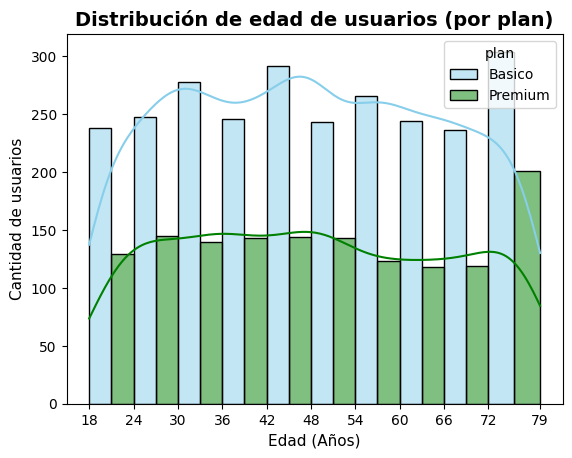

In [30]:
# Histograma para visualizar la edad (age)
edad_min = int(user_profile['age'].min())
edad_max = int(user_profile['age'].max())
bin_edges = np.linspace(edad_min, edad_max, 11).astype(int)
counts, _ = np.histogram(user_profile['age'].dropna(), bins=bin_edges)
sns.histplot(data=user_profile, x='age', hue='plan', bins=bin_edges, palette=['skyblue', 'green'], kde=True, multiple='dodge')
plt.title('Distribución de edad de usuarios (por plan)', fontsize=14, fontweight='bold')
plt.xlabel('Edad (Años)', fontsize=11)
plt.ylabel('Cantidad de usuarios', fontsize=11)
plt.xticks(bin_edges)
plt.show()

💡Insights: Según el gráfico, la distribución de las edades de los usuarios es equilibrada y está presente en ambos planes (Basico y Premium), reflejando una proporción similar en los diferentes rangos etarios con respecto a la participación general de cada plan (el plan Básico agrupa cerca del 64.88% de los clientes y el Premium un 35.12%).
- Distribución: La distribución de la edad es simétrica (con una media de 48 años y una mediana de 47 años). No presenta sesgos marcados hacia la izquierda ni hacia la derecha, abarcando desde los 18 hasta los 79 años de edad.

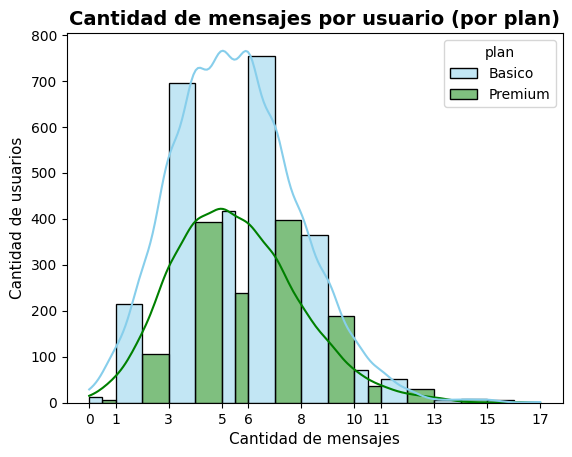

In [31]:
# Histograma para visualizar la cant_mensajes
msg_min = int(user_profile['cant_mensajes'].min())
msg_max = int(user_profile['cant_mensajes'].max())
bin_edges = np.linspace(msg_min, msg_max, 11).astype(int)
counts, _ = np.histogram(user_profile['cant_mensajes'].dropna(), bins=bin_edges)
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', bins=bin_edges, palette=['skyblue', 'green'], kde=True, multiple='dodge')
plt.title('Cantidad de mensajes por usuario (por plan)', fontsize=14, fontweight='bold')
plt.xlabel('Cantidad de mensajes', fontsize=11)
plt.ylabel('Cantidad de usuarios', fontsize=11)
plt.xticks(bin_edges)
plt.show()

💡Insights: Según la gráfica, la mayoría de los usuarios tienden a enviar entre 4 y 7 mensajes, con una media de 5.5 mensajes y una mediana de 5. No se aprecian diferencias significativas entre el uso de mensajes de los clientes del plan Básico(64.88%) frente al Premium(35.12%), muestran un comportamiento muy similar.
- Distribución: La distribución presenta un ligero sesgo hacia la derecha, jalonado por un valor extremo de 17 mensajes.

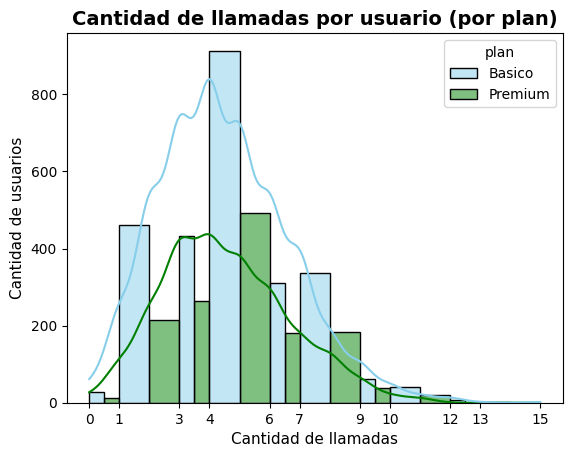

In [32]:
# Histograma para visualizar la cant_llamadas
llamadas_min = int(user_profile['cant_llamadas'].min())
llamadas_max = int(user_profile['cant_llamadas'].max())
bin_edges = np.linspace(llamadas_min, llamadas_max, 11).astype(int)
counts, _ = np.histogram(user_profile['cant_llamadas'].dropna(), bins=bin_edges)
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', bins=bin_edges, palette=['skyblue', 'green'], kde=True, multiple='dodge')
plt.title('Cantidad de llamadas por usuario (por plan)', fontsize=14, fontweight='bold')
plt.xlabel('Cantidad de llamadas', fontsize=11)
plt.ylabel('Cantidad de usuarios', fontsize=11)
plt.xticks(bin_edges)
plt.show()

💡Insights: Según la gráfica se observa que la mayoría de usuarios se concentra en un promedio de 4.5 llamadas y una mediana de 4. No se aprecian diferencias significativas entre el uso de mensajes de los clientes del plan Básico(64.88%) frente al Premium(35.12%), muestran un comportamiento muy similar.
- Distribución: La distribución es simétrica con un ligero sesgo a la derecha, jalonado por un valor extremo de 15 llamadas.

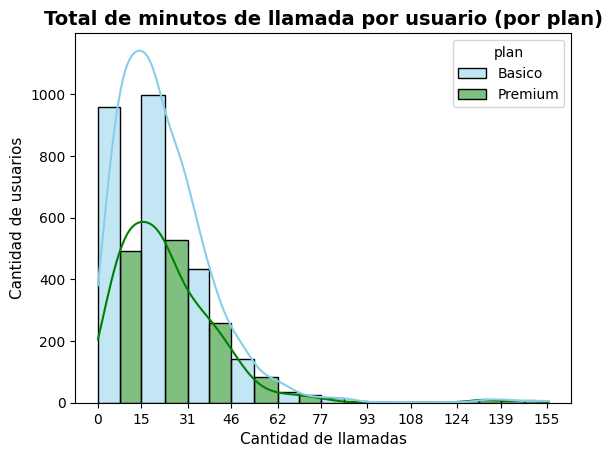

In [34]:
# Histograma para visualizar la total_minutos_llamada
llamadas_min = int(user_profile['total_minutos_llamada'].min())
llamadas_max = int(user_profile['total_minutos_llamada'].max())
bin_edges = np.linspace(llamadas_min, llamadas_max, 11).astype(int)
counts, _ = np.histogram(user_profile['total_minutos_llamada'].dropna(), bins=bin_edges)
sns.histplot(data=user_profile, x='total_minutos_llamada', hue='plan', bins=bin_edges, palette=['skyblue', 'green'], kde=True, multiple='dodge')
plt.title('Total de minutos de llamada por usuario (por plan)', fontsize=14, fontweight='bold')
plt.xlabel('Cantidad de llamadas', fontsize=11)
plt.ylabel('Cantidad de usuarios', fontsize=11)
plt.xticks(bin_edges)
plt.show()

💡Insights: Según la gráfica, la mayor concentración de usuarios se ubica en los rangos más bajos de consumo (de 0 a 31 minutos), con una media de 23.32 minutos y una mediana de 19.78 minutos. No se aprecian diferencias significativas entre el consumo de los clientes del plan Básico (64.88%) frente al Premium (35.12%), mostrando un comportamiento muy similar en su proporción.
- Distribución: La distribución presenta un sesgo moderado hacia la derecha, jalonado por un grupo de usuarios con un consumo más elevado que extiende la cola hasta un valor máximo de 155.69 minutos.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - **`total_minutos_llamada`**  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

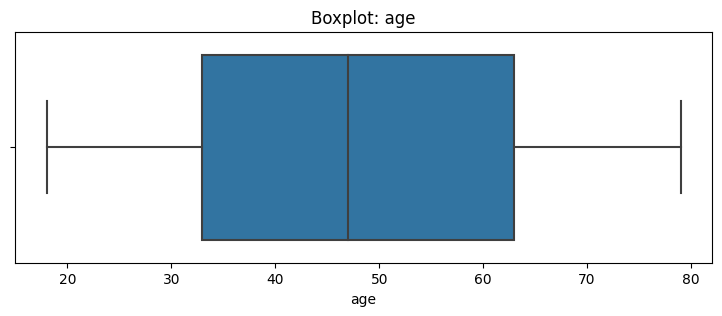

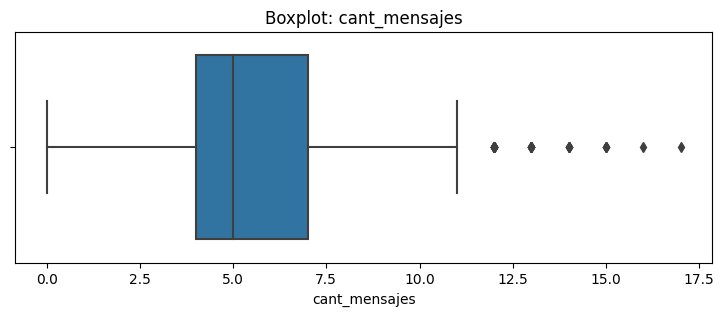

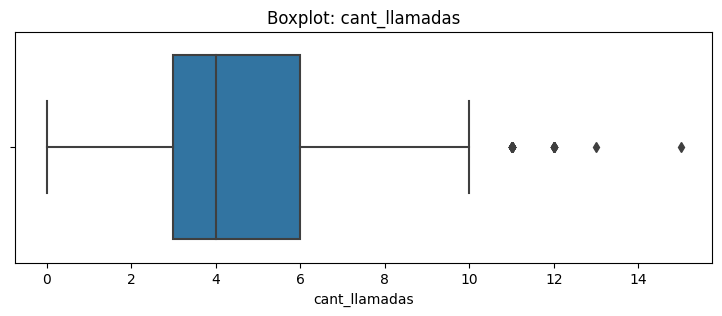

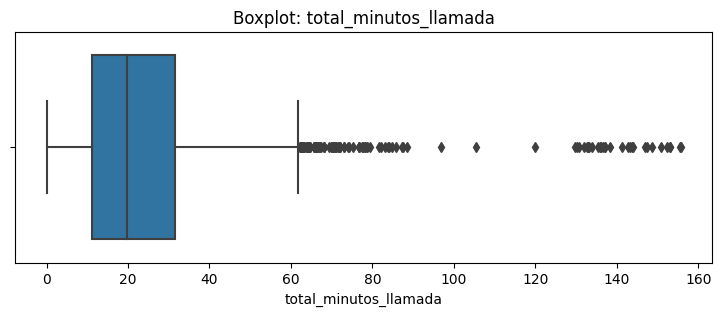

In [41]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'total_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(9, 3))
    sns.boxplot(x=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: No presenta outliers.
- cant_mensajes: Presenta outliers.
- cant_llamadas: Presenta outliers.
- **total_minutos_llamada:** Presenta outliers.

In [46]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'total_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3-Q1
    upper = Q3 + 1.5*IQR
    cant_outliers = (user_profile[col] > upper).sum()
    print(f"Variable: {col} | Límite superior: {upper:.2f} | Cantidad de outliers: {cant_outliers}")

Variable: cant_mensajes | Límite superior: 11.50 | Cantidad de outliers: 46
Variable: cant_llamadas | Límite superior: 10.50 | Cantidad de outliers: 30
Variable: total_minutos_llamada | Límite superior: 61.86 | Cantidad de outliers: 109


In [51]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,total_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- **cant_mensajes:** sí mantener los outliers, porque con un límite superior de 11.50 y un máximo de 17 mensajes, los 46 casos detectados representan apenas un 1.43% del total de la base. Corresponden a un comportamiento de consumo real y orgánico de usuarios altamente activos, por lo que eliminarlos recortaría artificialmente la cola derecha de la distribución. El 58.70% de los outliers pertenecen al plan Básico y el 41.30% al Premium.
- **cant_llamadas:** sí mantener los outliers, porque el límite superior se sitúa en 10.50 y el máximo alcanza 15 llamadas, con 30 registros atípicos que equivalen al 0.93% de los usuarios. Esta baja proporción responde a hábitos legítimos de comunicación, por lo que conservarlos preserva la integridad de los datos. El 73.33% de los valores extremos provienen del plan Básico frente a un 26.67% del Premium.
- **total_minutos_llamada:** sí mantener los outliers, porque aunque el límite superior es de 61.86 minutos y se registran 109 valores extremos (un 3.39% de la base) que llegan hasta 155.69 minutos, estos consumos son completamente válidos. Descartar este grupo eliminaría información valiosa. El 60.55% de los outliers se ubican en el plan Básico y el 39.45% en el Premium.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [54]:
# Crear columna grupo_uso
user_profile['grupo_uso'] = np.where(
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    'Bajo uso',
    np.where(
        (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10),
        'Uso medio',
        'Alto uso'
    )
)
display(user_profile['grupo_uso'].value_counts(normalize=True) * 100)

Uso medio    73.575
Bajo uso     19.450
Alto uso      6.975
Name: grupo_uso, dtype: float64

In [55]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,total_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [61]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = np.where(
    user_profile['age'] < 30,
    'Joven',
    np.where(
        user_profile['age'] < 60,
        'Adulto',
        'Adulto Mayor'
    )
)
display(user_profile['grupo_edad'].value_counts(normalize=True) * 100)

Adulto          50.45
Adulto Mayor    30.55
Joven           19.00
Name: grupo_edad, dtype: float64

In [57]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,total_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

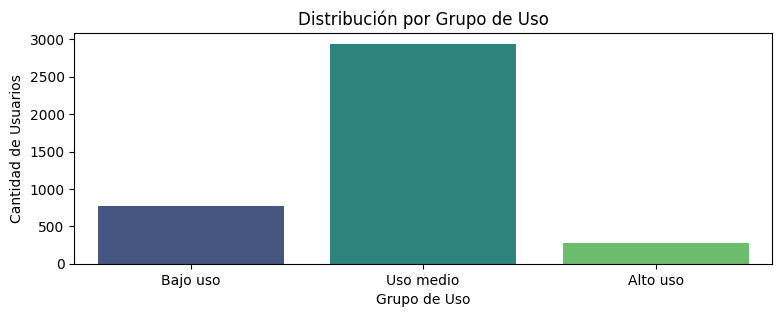

In [59]:
# Visualización de los segmentos por uso
plt.figure(figsize=(9, 3))
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], palette='viridis')
plt.title('Distribución por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Usuarios')
plt.show()

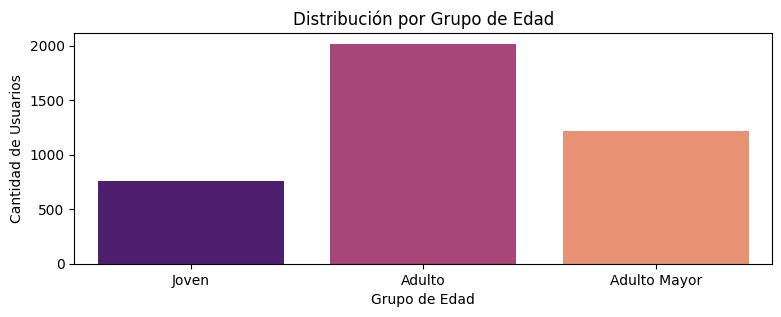

In [62]:
# Visualización de los segmentos por edad
plt.figure(figsize=(9, 3))
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], palette='magma')
plt.title('Distribución por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- En el conjunto de datos de usuarios df*users_latam.csv* de ConnectaTel, se identificaron valores nulos en la columna `city`, representando el 11.72% (469 filas ausentes, de las cuales 96 correspondían al carácter centinela "?""). Asimismo, la columna `age` contenía un valor centinela extremo de -999, el cual alteraba de forma desproporcionada la desviación estándar y las medidas de tendencia central; este valor fue debidamente tratado reemplazándolo por la mediana de la distribución.
- En el conjunto de fechas de registro `reg_date`, se detectó un pequeño porcentaje de registros con fechas futuras correspondientes al año 2026 (40 filas, aproximadamente el 1%), las cuales fueron marcadas como nulas por exceder el periodo de estudio establecido hasta 2024.
- En el registro de uso df*usage.csv*, se encontraron nulos estructurales en `duration` y `length` (55.19% y 44.74% respectivamente), los cuales corresponden a un comportamiento del tipo Missing At Random (MAR) debido a que los mensajes de texto no generan duración de llamada y las llamadas de voz no generan longitud de mensaje.

🔍 **Segmentos por Edad**
- La distribución etaria de los usuarios de ConnectaTel es marcadamente simétrica, con una edad media de 48.12 años, una mediana de 47 años y un rango que abarca desde los 18 hasta los 79 años.
- Al segmentar los datos cruzándolos con el tipo de plan, se observa que la proporción de usuarios se mantiene estable y equilibrada en todos los rangos etarios, sin que se evidencie un sesgo o concentración de un plan específico en una generación o grupo de edad en particular. 

📊 **Segmentos por Nivel de Uso**
- El comportamiento de uso mensual por usuario muestra que el promedio de mensajes se sitúa en 5.52 (con una mediana de 5) y el total de minutos de llamadas promedia 23.31 minutos (con una mediana de 19.78 minutos).
- A nivel general, los clientes presentan un consumo moderado y homogéneo en los servicios tradicionales (voz y SMS), encontrándose una distribución con un ligero sesgo hacia la derecha impulsado por pequeños grupos de mayor actividad. No existen diferencias estructurales drásticas en el consumo entre los clientes del plan Básico y los del Premium más allá de los límites propios de cada paquete.
- Se detectaron cuentas asociadas al plan Básico con un registro de cero minutos de llamadas y cero mensajes durante el ciclo analizado. Representan un riesgo latente de abandono (churn). Al no utilizar los servicios contratados, la probabilidad de que cancelen la suscripción en el corto plazo es muy alta si no se implementan estrategias de reactivación.

💡 **Recomendaciones**
- **Oportunidad de cambio de segmento (Plan Upgrade)**:
Los usuarios de alto consumo del plan Básico son candidatos ideales para campañas comerciales automatizadas. Al mostrarles que su consumo real supera las capacidades de su plan actual, se les puede ofrecer una migración fluida al plan Premium, destacando los beneficios de contar con mayores límites y evitando que experimenten cobros excesivos por excedentes.
- **Optimización de planes actuales:** Dado que la penetración del plan Básico abarca al 64.88% de los clientes frente a un 35.12% del plan Premium, y considerando que los patrones de consumo en llamadas y mensajes son relativamente moderados, se recomienda revisar los umbrales de minutos y gigabytes incluidos para diseñar opciones intermedias (por ejemplo, un plan flexible o híbrido) que capturen a aquellos usuarios que no alcanzan a justificar el costo del plan Premium pero sobrepasan los límites del Básico.
- **Estrategias de retención basadas en perfiles:** Implementar campañas de fidelización preventivas enfocadas en los segmentos con mayor antigüedad o aquellos que muestran comportamientos atípicos de consumo (outliers de uso extremo en llamadas o datos), con el fin de mitigar la tasa de cancelación (churn).
- **Gobierno de datos:** Fortalecer los procesos de captura de información en los sistemas de origen para evitar la introducción de valores centinelas (como -999 en edades o ? en ciudades) y asegurar la consistencia temporal de los registros desde el ingreso del cliente.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`